# Global earthquake clustering — Phases 1-4 + Bonus
This notebook only clones/pulls the GitHub repo and runs the logic from `src/`.
To change the code, edit the files under `src/` on GitHub and re-run this notebook (the clone cell pulls automatically).


Computational Intelligence Course Project — Ferdowsi University of Mashhad, Department of Computer Engineering

Team members' names and student IDs: Amirhossein Kooshesh 4011262429

This notebook reproduces Phases 1-4 (plus the optional bonus section) of the project: Phase 1 cleans the global earthquake dataset, visualizes event locations and selected regions, computes local density via nearest-neighbor distances, and records predictions P1-P4 before any clustering is run. Phase 2 runs K-Means (raw lat/lon vs. the 3D unit-sphere representation, choice of k, and cluster analysis). Phase 3 runs DBSCAN on the full dataset and Single/Average Link hierarchical clustering on the shared sample S. Phase 4 evaluates all four methods together on S (summary table, pairwise ARI, resampling-stability experiment) and concludes with the P1-P4 verdicts and the final per-scenario recommendation. The bonus section (optional) covers a controlled-perturbation robustness check for K-Means/DBSCAN and an HDBSCAN-vs-DBSCAN comparison. All logic lives in `src/`; this notebook only clones the repo and calls it.


In [ ]:
import os

CONTENT_DIR = "/content"  # fixed, known root -- re-running this cell is always safe
REPO_URL = "https://github.com/AHK-0214/CI_Clustering.git"
REPO_DIR = os.path.join(CONTENT_DIR, "CI_Clustering")

os.chdir(CONTENT_DIR)  # undo any previous %cd before deciding anything

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL}
else:
    print("Repo already exists; pulling latest changes...")
    !cd {REPO_DIR} && git pull

os.chdir(REPO_DIR)
print("Current directory:", os.getcwd())

# Force a fresh import of src/* in the cell below, even if this kernel already
# imported an older version of it earlier in this session. Without this, a
# `git pull` updates the files on disk but Python keeps serving the OLD cached
# module from sys.modules, which is the classic cause of a stale
# `KeyError: 'p1_structures'` (or any other "it's right there in the code but
# still fails") after pulling new code without restarting the runtime.
import sys
for _mod_name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_mod_name]


In [ ]:
!pip install -q -r requirements.txt

## Dataset
Pick one of two options:

**Option 1 (recommended, simplest):** download `database.csv` from Kaggle and upload it here.

**Option 2:** upload your own `kaggle.json` so kagglehub can download it automatically.

In [ ]:
import os
os.makedirs("data", exist_ok=True)

USE_KAGGLEHUB = False  # set to True to try automatic download via kagglehub

if USE_KAGGLEHUB:
    from google.colab import files
    print("Upload your kaggle.json file:")
    uploaded = files.upload()
    os.makedirs("/root/.kaggle", exist_ok=True)
    for fname in uploaded:
        os.rename(fname, "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)
else:
    if not os.path.exists("data/database.csv"):
        from google.colab import files
        print("Upload the database.csv file (from the usgs/earthquake-database Kaggle dataset):")
        uploaded = files.upload()
        for fname in uploaded:
            os.rename(fname, "data/database.csv")
    else:
        print("data/database.csv already exists.")

In [4]:
import sys, importlib
sys.path.insert(0, ".")

# Import (or re-import) the current on-disk version of src.phase1 -- see the
# cache-busting note in the clone/pull cell above.
import src.phase1 as _phase1_mod
importlib.reload(_phase1_mod)
from src.phase1 import run_phase1

import matplotlib.pyplot as plt
plt.ioff()  # run_phase1() builds several matplotlib figures; ioff() plus the
            # plt.close(fig) calls inside src/viz.py stop them from being
            # auto-printed here a second time -- each figure is only shown once,
            # later, in its own cell under Questions A/B/D below.
results = run_phase1(save_outputs=True)
plt.ion()

print("Total earthquakes after cleaning (Type == Earthquake):", results["n_total"])
print("Base seed (s):", results["seed_base"])


plotly is not installed; skipping plot_world_map_geo. Install it with `pip install plotly` to enable this map.
Total earthquakes after cleaning (Type == Earthquake): 23232
Base seed (s): 429


# Phase 1 — Data exploration, regions, density and predictions
Raw-data exploration only (no clustering algorithm run yet): the world map and the three Phase-1 regions, the density metric, why plain lat/lon Euclidean distance is misleading, and predictions P1-P4 recorded before seeing any clustering output.

## Question A — map and three regions

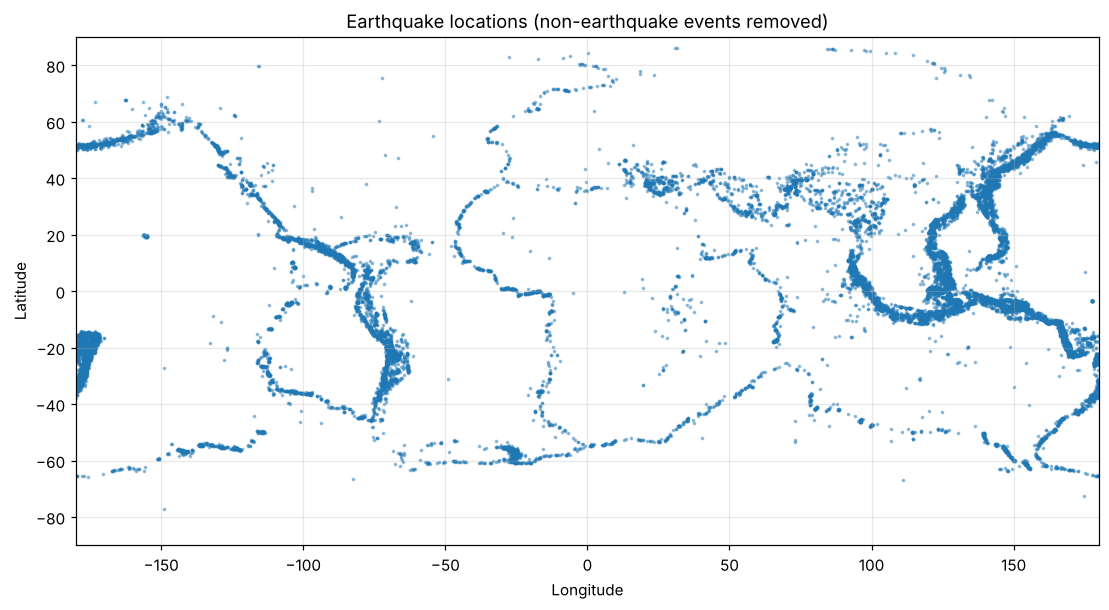

In [5]:
results["figures"]["map"]

Real-world map with country borders/coastlines (hover to see lat/lon), so each earthquake can be tied to an actual country or region instead of a bare scatter plot:

In [6]:
results["figures"]["map_geo"]

**Note:** the region near ±180° longitude (e.g. the Tonga-Kermadec trench) may look split into two pieces at the left/right edge of the flat map above, because any flat map of a sphere necessarily has a "seam" somewhere. This is only a 2D-display limitation; the distance calculations (conversion to xyz on the unit sphere in `src/geo.py`) do not have this problem, and points on either side of this line are correctly treated as near each other. (Full explanation: Section C of the English report, `report_phase1_en.docx`.)


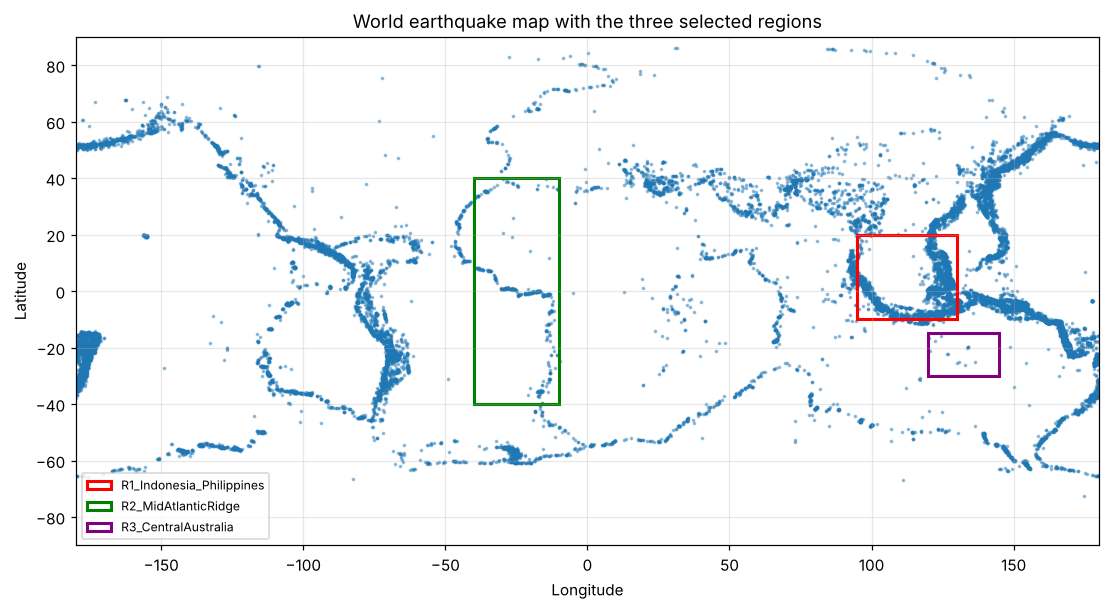

In [7]:
results["figures"]["map_regions"]

In [8]:
results["region_table"]

,region,lat_range,lon_range,count,reason
0,R1_Indonesia_Philippines,"[-10.0, 20.0]","[95.0, 130.0]",3163,Part of the Pacific Ring of Fire; expected to show very high density and a multi-part / elongated pattern along fault lines.
1,R2_MidAtlanticRidge,"[-40.0, 40.0]","[-40.0, -10.0]",362,"A mid-ocean ridge; expected to show an elongated, narrow pattern with medium-to-low density along a well-defined line."
2,R3_CentralAustralia,"[-30.0, -15.0]","[120.0, 145.0]",14,An intraplate region far from plate boundaries; expected to show very low density and irregular scattering (the low-density sample).


## Question B — density (distance to the 10th neighbor)

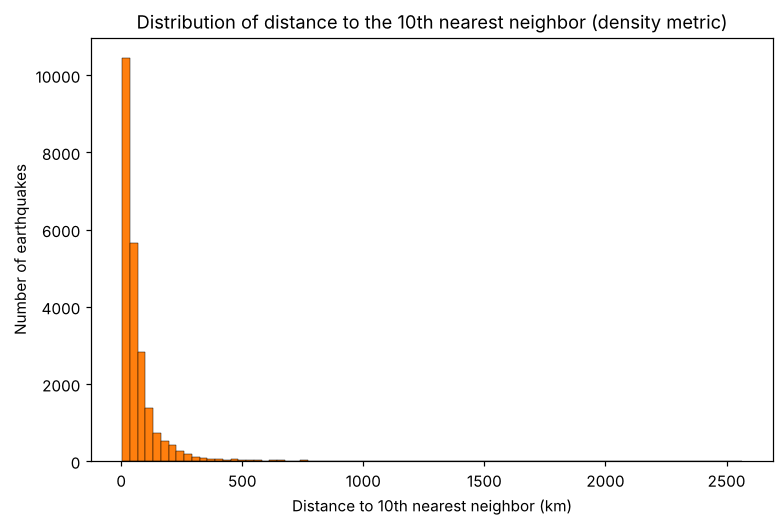

In [9]:
results["figures"]["hist"]

In [10]:
results["density_table"]

,region,count,Q1 (km),median (km),Q3 (km)
0,R1_Indonesia_Philippines,3163,24.24,39.91,68.84
1,R2_MidAtlanticRidge,362,54.17,87.13,199.24
2,R3_CentralAustralia,14,786.78,1089.31,1101.04


## Question C — why plain Euclidean distance on lat/lon is misleading

In [11]:
print(results["distance_explanation"])


Computing the plain Euclidean distance directly on the raw Latitude and Longitude
columns is misleading, because these two quantities are angles, not Cartesian
coordinates on a flat plane:

1) Discontinuity at 180 degrees longitude:
   Two points at longitude 179 and -179 degrees (e.g. near the International Date
   Line in the Pacific Ocean) are only about 2 degrees (~222 km) apart in reality,
   but their raw Euclidean distance along the longitude axis computes to 358
   degrees -- nearly the maximum possible value. These two points, which are in
   fact neighbors, appear to be very far apart under this incorrect metric.

2) Distortion near the poles:
   The length of one degree of longitude shrinks with cos(latitude). Near the
   poles, a large difference in longitude can correspond to a very small real
   distance, while the raw Euclidean distance computes it as large.

Representing points in 3D on the unit sphere (x = cos(phi) cos(lambda),
y = cos(phi) sin(lambda), z = sin(phi)) r

## Question D — predictions P1 through P4

In [12]:
import pandas as pd
pd.set_option("display.max_colwidth", None)

# Full text of predictions P1-P4 (prediction / reason / rejection criterion),
# copied in from the report's Section D so it is readable directly in the notebook
# rather than only in report_phase1_en.docx.
for name, p in results["predictions"].items():
    print(f"--- {name} ---")
    print("Prediction:", p["prediction"])
    print("Reason:", p["reason"])
    print("Rejection criterion:", p["rejection_criterion"])
    print()

pd.DataFrame(results["predictions"]).T


--- P1 ---
Prediction: The elongated structure most likely to be split across several K-Means clusters (k=12) is the Mid-Atlantic Ridge; also parts of the Ring of Fire along the west coast of South America and East Asia, which are long and elongated.
Reason: K-Means builds clusters with a Voronoi decision boundary around k centers, which suits compact/spherical clusters. A narrow, elongated structure (such as a fault line) whose length exceeds the typical diameter of a Voronoi cell will be covered by several neighboring centers and fragmented across multiple clusters.
Rejection criterion: If, after running the algorithm, the entire length of the Mid-Atlantic Ridge is found within one or two clusters (rather than three or more), this prediction is rejected.

--- P2 ---
Prediction: As eps increases from a small to a large value, the percentage of noise points decreases monotonically and the size of the largest cluster increases monotonically. At large eps, because of the chaining phenome

,prediction,reason,rejection_criterion
P1,"The elongated structure most likely to be split across several K-Means clusters (k=12) is the Mid-Atlantic Ridge; also parts of the Ring of Fire along the west coast of South America and East Asia, which are long and elongated.","K-Means builds clusters with a Voronoi decision boundary around k centers, which suits compact/spherical clusters. A narrow, elongated structure (such as a fault line) whose length exceeds the typical diameter of a Voronoi cell will be covered by several neighboring centers and fragmented across multiple clusters.","If, after running the algorithm, the entire length of the Mid-Atlantic Ridge is found within one or two clusters (rather than three or more), this prediction is rejected."
P2,"As eps increases from a small to a large value, the percentage of noise points decreases monotonically and the size of the largest cluster increases monotonically. At large eps, because of the chaining phenomenon between regions of different density, one giant cluster absorbs most of the dense regions. We do not expect a single eps to cluster both dense regions (e.g. R1) and sparse regions (e.g. R3) well simultaneously, because by definition DBSCAN uses one global eps, and the order-of-magnitude difference in density between regions (observed in Phase 1-B) makes this trade-off difficult.","DBSCAN defines core points based on counting neighbors within a fixed radius eps; increasing eps enlarges each point's neighborhood radius and therefore increases the chance of reaching the min_samples threshold, and also connects neighboring clusters together.","If, in the Phase 3-A table, a range of eps is found in which the noise percentage in R1 (dense) stays low AND R3 (sparse) remains reasonably separated from noise, the second part of this prediction is rejected."
P3,"Single Link is more prone to forming one very large cluster and several very small clusters (a 'rich-get-richer' structure), whereas Average Link produces more balanced clusters.","In Single Link, the distance between two clusters equals the minimum distance between any member of the two clusters; this criterion is very sensitive to the chaining phenomenon — a single thin chain of nearby points is enough to connect two large masses. Average Link uses the average of all pairwise distances, which is more robust to such thin bridges and produces more compact, balanced clusters.","If, in Phase 3-C, the cluster-size distribution of Average Link turns out to be more unbalanced than that of Single Link (e.g. higher variance in cluster size), this prediction is rejected."
P4,"For scenario A (zoning/regionalization), we consider K-Means more suitable because it assigns every point to exactly one cluster (100% coverage) and the number of regions (k) can be set directly in the range 10 to 20. For scenario B (structure discovery), we consider DBSCAN more suitable because it does not impose the number of clusters in advance and allows outlier points to be labeled as noise.",K-Means's assumptions (spherical clusters around a center) are more consistent with scenario A's goal (describable regions with full coverage); DBSCAN's assumption (density connectivity) is more consistent with scenario B's goal (discovering belts without fixing k).,"If, in Phase 4, it turns out that DBSCAN with a suitable eps produces near-complete coverage and regions that are just as describable for scenario A, or that K-Means performs acceptably at discovering the non-spherical belts of scenario B, the corresponding part of this prediction is rejected."


### Question D (continued) — where are the structures named in P1?
This is a subsection of Question D / prediction P1 above, not a separate question. Still raw data (no clustering algorithm has been run) — just locating the candidate elongated structures mentioned in P1's reasoning (Mid-Atlantic Ridge, South America's west coast, the East Asia / western Pacific arc) on the map.


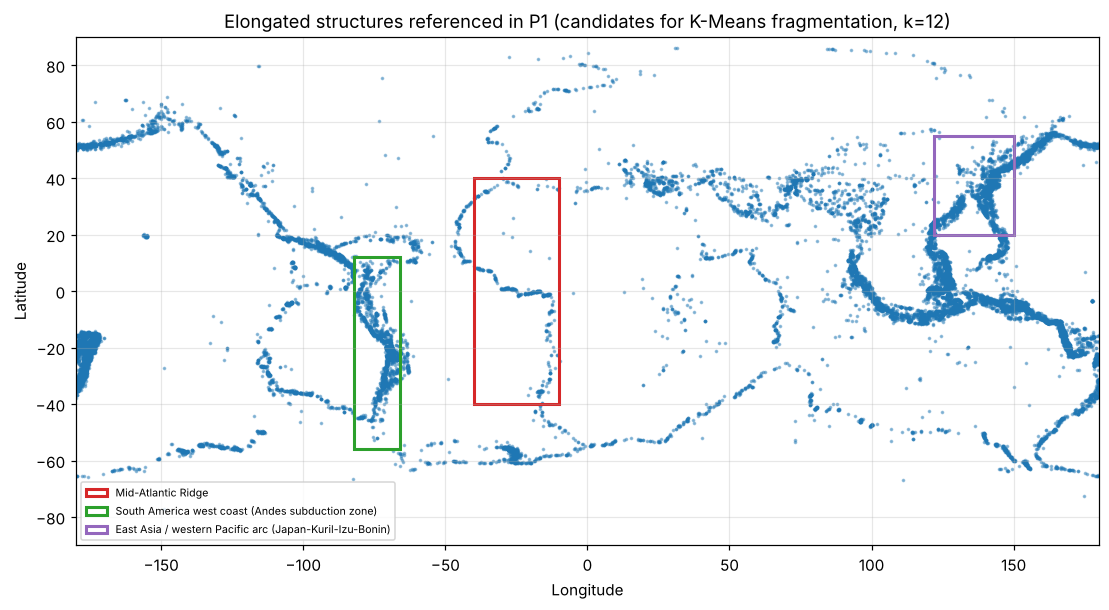

In [13]:
results["figures"]["p1_structures"]


# Phase 2 — K-Means


In [14]:
import src.phase2 as _phase2_mod
importlib.reload(_phase2_mod)
from src.phase2 import run_phase2

results2 = run_phase2(df=results["df"])
print(f"Selected k = {results2['final_k']}")


Selected k = 12


## Question A — raw (lat, lon) vs. 3D sphere, and the initialization baseline


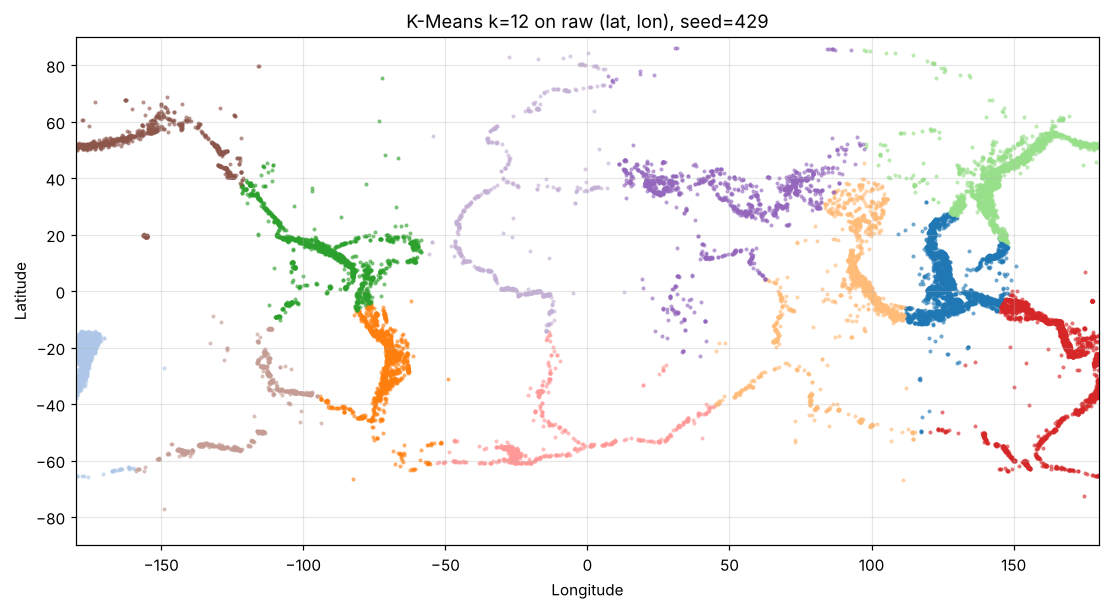

In [15]:
results2["figures"]["kmeans_2d"]


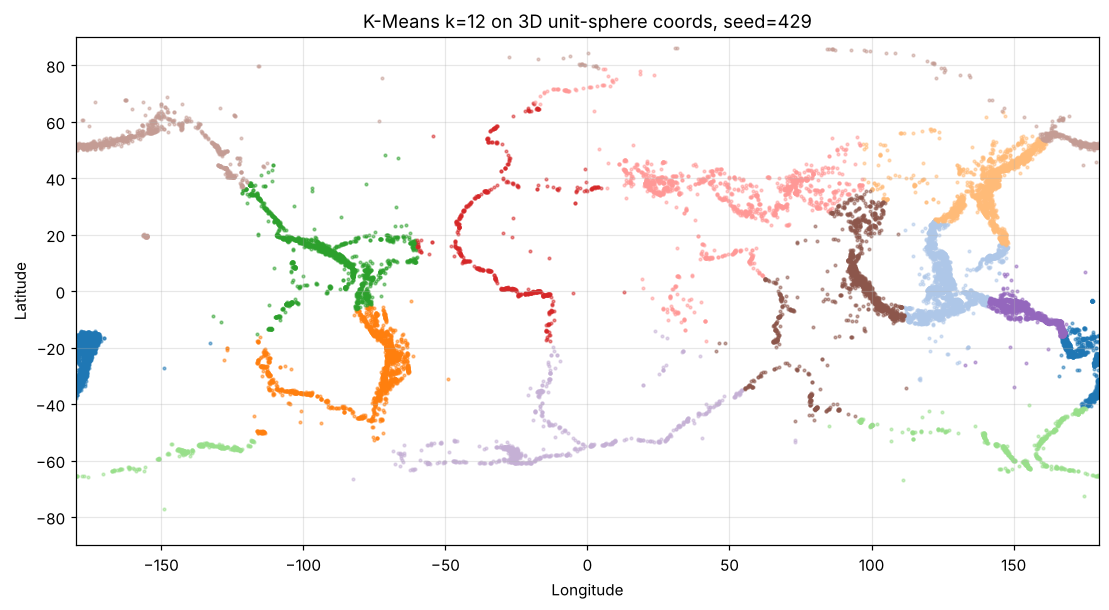

In [16]:
results2["figures"]["kmeans_3d"]


In [17]:
print(f"ARI (raw lat/lon vs 3D sphere, both k={results2['final_k']}, seed=s): "
      f"{results2['ari_2d_vs_3d']:.3f}")
print(f"ARI (3D sphere, seed=s vs seed=s+1, pure init-variability baseline): "
      f"{results2['ari_3d_baseline_init']:.3f}")
print()
print(results2["qa_discussion"])


ARI (raw lat/lon vs 3D sphere, both k=12, seed=s): 0.757
ARI (3D sphere, seed=s vs seed=s+1, pure init-variability baseline): 0.949

ARI between the raw-(lat,lon) run and the 3D-sphere run (both k=12, seed=429) is 0.757. As a baseline, running the 3D version twice with different seeds (429 and 430, pure initialization variability, same representation) gives ARI=0.949. The 2D-vs-3D disagreement is larger than the pure initialization-noise baseline, which supports the idea that the coordinate representation itself (not just random initialization) changes the clustering. A visible difference on the map is near the 180-degree meridian / high latitudes: raw (lat, lon) Euclidean distance treats longitude as if its physical length were constant and independent of latitude, and it does not 'wrap around' at +/-180 degrees, so points that are geographically close across the date line or near the poles can be pulled into different raw-(lat,lon) clusters than they are in the 3D representation, whe

## Question B — choosing k


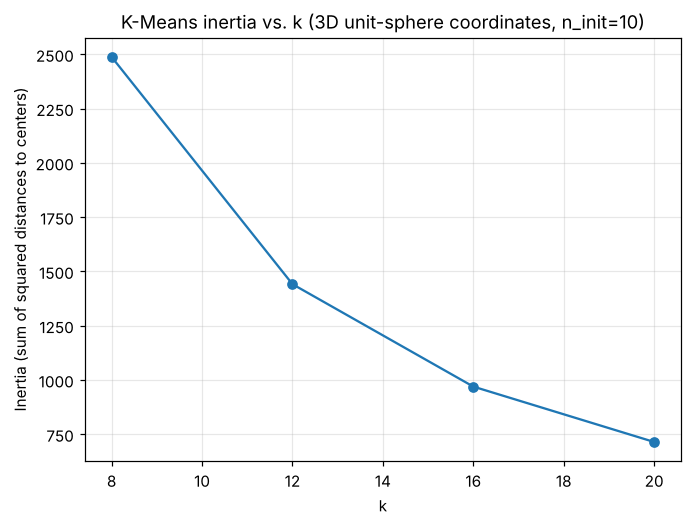

In [18]:
results2["figures"]["inertia"]


In [19]:
results2["kb_table"]  # inertia + Silhouette (computed only on sample S) for k in {8,12,16,20}


,k,inertia,silhouette_on_S
0,8,2487.683670,0.463744
1,12,1441.121903,0.504457
2,16,969.336959,0.521528
3,20,714.282609,0.520774


In [20]:
print(results2["selected_k_justification"])


The inertia curve decreases smoothly with k with no single sharp elbow (common with geographically spread, non-spherical data), so it does not pick one k on its own. Silhouette on S is generally low across all four values of k (compact, well-separated clusters are not what this data looks like at any of these k's), and it also does not single out one best k. For scenario A (zoning into roughly 10-20 describable regions), we pick k=12 as a value in the middle of the requested range that keeps regions at a size an organization can still describe individually, rather than over-splitting (k=20) or under-splitting (k=8) the map; this is a judgment call based on the application, since the two numeric criteria here do not give a clear signal.


## Question C — analysis of the selected k output (revisiting P1)


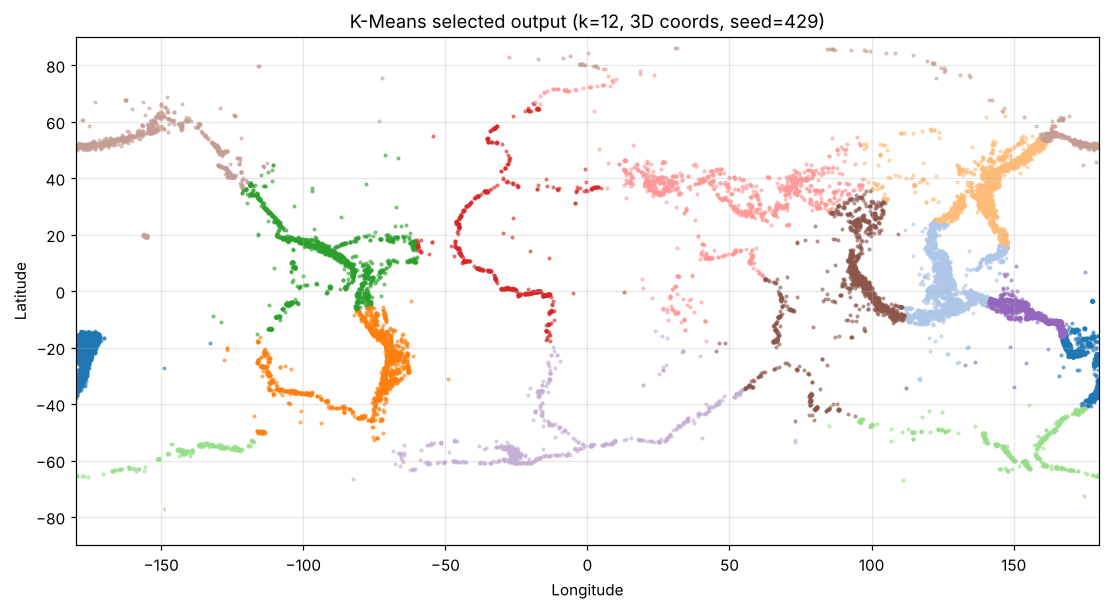

In [21]:
results2["figures"]["kmeans_selected"]


In [22]:
print("Cluster breakdown per Phase-1 region (cluster_id, count), largest first:")
for region, breakdown in results2["region_cluster_breakdown"].items():
    print(f"  {region}: {breakdown}")
print()
print(results2["qc_discussion"])


Cluster breakdown per Phase-1 region (cluster_id, count), largest first:
  R1_Indonesia_Philippines: [(1, 2456), (10, 707)]
  R2_MidAtlanticRidge: [(6, 303), (9, 59)]
  R3_CentralAustralia: [(1, 12), (8, 2)]

Looking at the k=12 output, region 'R1_Indonesia_Philippines' has its points spread across 2 different K-Means clusters ([(1, 2456), (10, 707)]), rather than sitting in one cluster. K-Means assigns every point to its nearest of k centers (a Voronoi partition); a region whose geographic extent is larger than the typical diameter of a Voronoi cell at this k gets cut by one or more of these straight-line boundaries, independent of whether the region is itself geologically a single structure. Revisiting prediction P1: the qualitative direction of P1 (elongated structures get fragmented across several K-Means clusters) is supported by this example; the part of P1 that needs refining is the identity of *which* structure is the clearest case, since that depends on where the k centers hap

## Question D — geographic spread (max pairwise distance) per cluster


In [23]:
results2["span_table"]  # max_span_km per cluster; is_lower_bound_estimate flags subsampled (>1500-pt) clusters


,cluster,n_points,max_span_km,is_lower_bound_estimate,subsample_size
0,7,1307,10943.7,False,1307
1,10,1539,9432.4,True,1500
2,6,517,9377.3,False,517
3,9,890,9277.9,False,890
4,11,1416,9021.3,False,1416
5,4,1700,8917.5,True,1500
6,5,800,8615.8,False,800
7,2,1848,7763.1,True,1500
8,1,3690,6269.9,True,1500
9,8,2758,5842.9,True,1500


In [24]:
print(results2["qd_discussion"])


The widest cluster in the selected k=12 output is cluster 7, with a max pairwise great-circle span of about 10944 km. A span of this size spans multiple countries/plate segments, which is large for an organization that wants each of scenario A's 10-20 zones to be a 'describable' region; such a cluster reads more like several geographically distinct areas that K-Means merged because their centers happened to be closer to this center than to any other. If this is judged unacceptable, increasing k (more, smaller Voronoi cells) is the most direct fix within K-Means; alternatively, a density-based or hierarchical method could be used instead if the strict single-partition, full-coverage requirement of scenario A were relaxed.


# Phase 3 — DBSCAN and hierarchical clustering


In [25]:
import src.phase3 as _phase3_mod
importlib.reload(_phase3_mod)
from src.phase3 import run_phase3

results3 = run_phase3(df=results["df"], sample_S=results2["sample_S"])
print("DBSCAN eps values plotted below:", results3["qa_eps_plotted"])


DBSCAN eps values plotted below: [500, 75]


## Question A — DBSCAN on the full data (eps in {75, 200, 500} km)


In [26]:
results3["qa_table"]  # n_clusters, noise%, largest cluster size/share, # clusters with 10-19 points


,eps_km,n_clusters,noise_pct,largest_cluster_size,largest_cluster_share_pct,n_clusters_10_19_points
0,75,179,17.20,3438,14.80,89
1,200,84,3.66,15396,66.27,34
2,500,13,0.74,21075,90.72,4


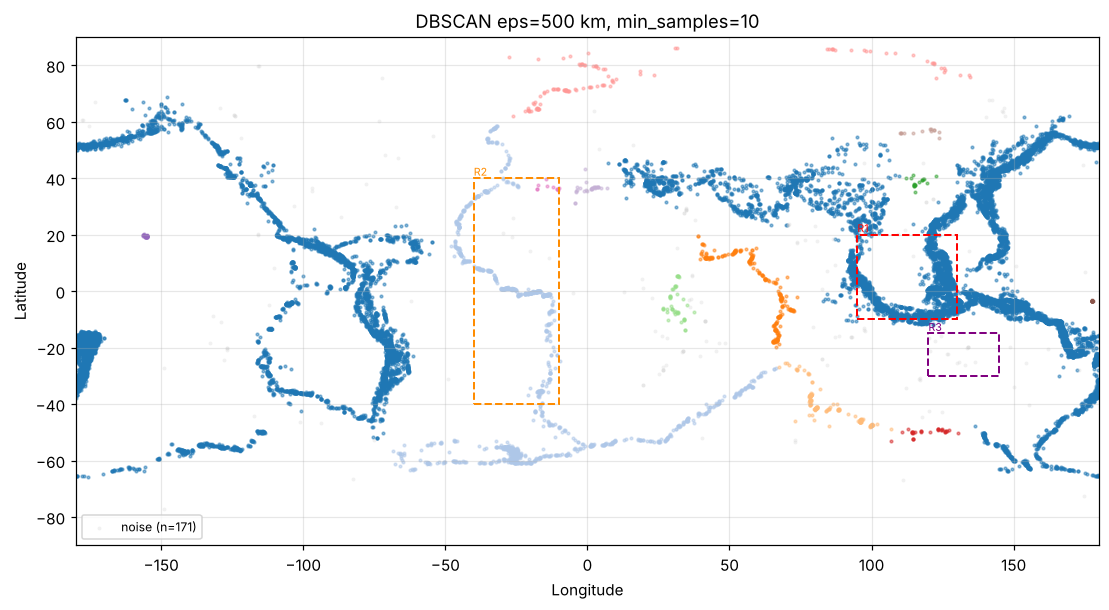

In [27]:
results3["figures"]["dbscan"][results3["qa_eps_plotted"][0]]


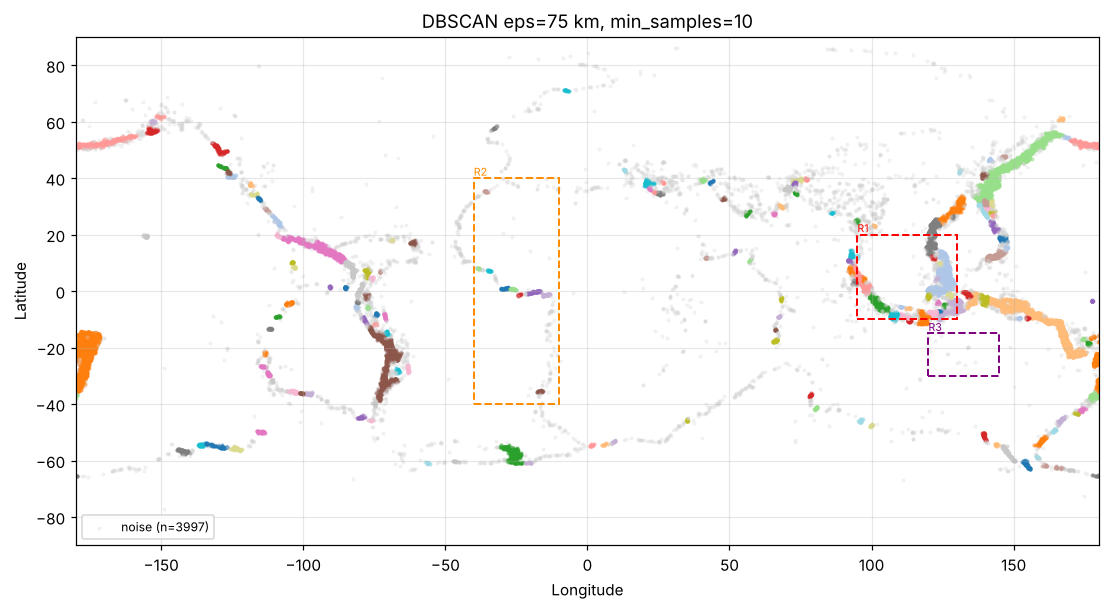

In [28]:
results3["figures"]["dbscan"][results3["qa_eps_plotted"][1]]


In [29]:
print(results3["qa_discussion"])


As eps grows from 75 to 500 km, the noise percentage and the number of clusters both move monotonically down while the largest cluster's share grows (see the table): more points fall within eps of an existing core point, so points that used to be isolated become reachable and small clusters chain together into fewer, larger ones. This matches the direction predicted in P2. Whether a single eps handles both dense and sparse regions well at the same time is examined directly in Question B below.


## Question B — density per region, per eps


In [30]:
results3["qb_table"]  # per (eps, region): % noise, % in main cluster, shared main cluster with another region


,eps_km,region,pct_noise,pct_in_main_cluster,main_cluster_id,shared_main_cluster_with
0,75,R1_Indonesia_Philippines,7.8,44.4,1.0,None
1,75,R2_MidAtlanticRidge,40.3,14.4,28.0,None
2,75,R3_CentralAustralia,100.0,0.0,NaN,None
3,200,R1_Indonesia_Philippines,0.7,99.1,0.0,None
4,200,R2_MidAtlanticRidge,18.8,47.0,16.0,None
5,200,R3_CentralAustralia,100.0,0.0,NaN,None
6,500,R1_Indonesia_Philippines,0.0,100.0,0.0,None
7,500,R2_MidAtlanticRidge,1.4,96.1,1.0,None
8,500,R3_CentralAustralia,100.0,0.0,NaN,None


In [31]:
print(results3["qb_conclusion"])
print()
print(f"Final eps chosen for scenario B: {results3['final_eps_scenario_b']} km")
print(results3["qb_final_eps_reason"])


Criterion for 'good': noise below 30% in every one of the three Phase-1 regions, with no two regions sharing the same main cluster. None of the tested eps values satisfies this simultaneously: at eps=75 km the worst-affected region reaches 100.0% noise (consistent with the larger 10th-neighbor distances found for the sparse region in Phase 1-B), while at eps=500 km per-region noise drops to as low as 0.0% but regions start sharing a main cluster instead -- the gap between within-region and between-region neighbor distances is not large enough for one global eps to separate both scales at once.

Final eps chosen for scenario B: 75 km
For scenario B we select eps=75 km: among the tested values it gives the best available balance for the three Phase-1 regions, with a worst-case per-region noise of 100.0% and a best-case of 7.8% (see the per-region table), which is the closest match to scenario B's goal of finding belts/clusters without forcing every point into a cluster.


## Question C — hierarchical clustering on the shared sample S


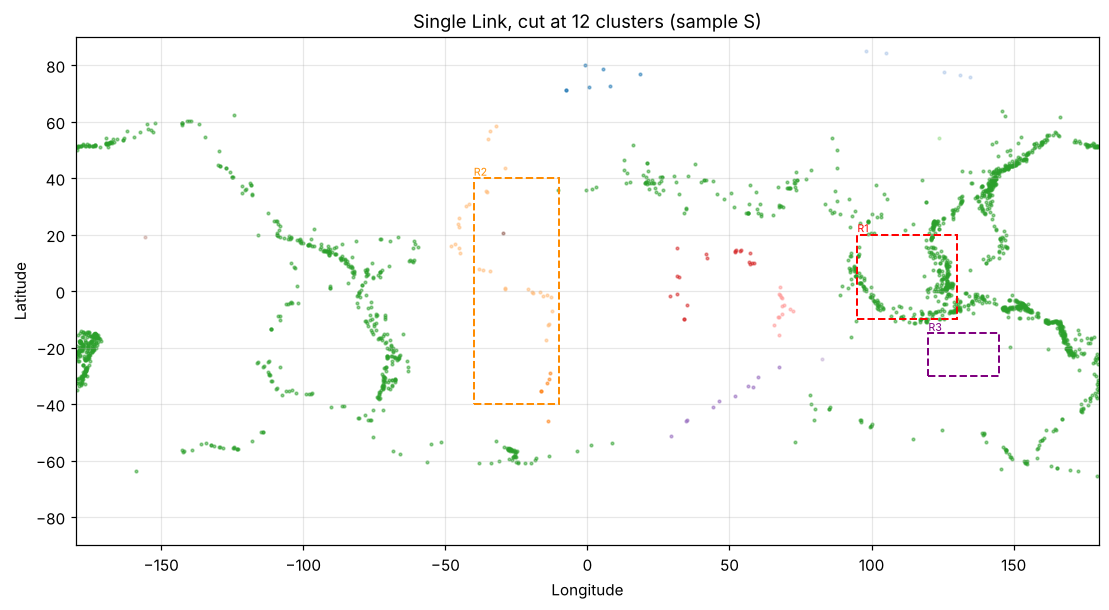

In [32]:
results3["figures"]["single_link"]


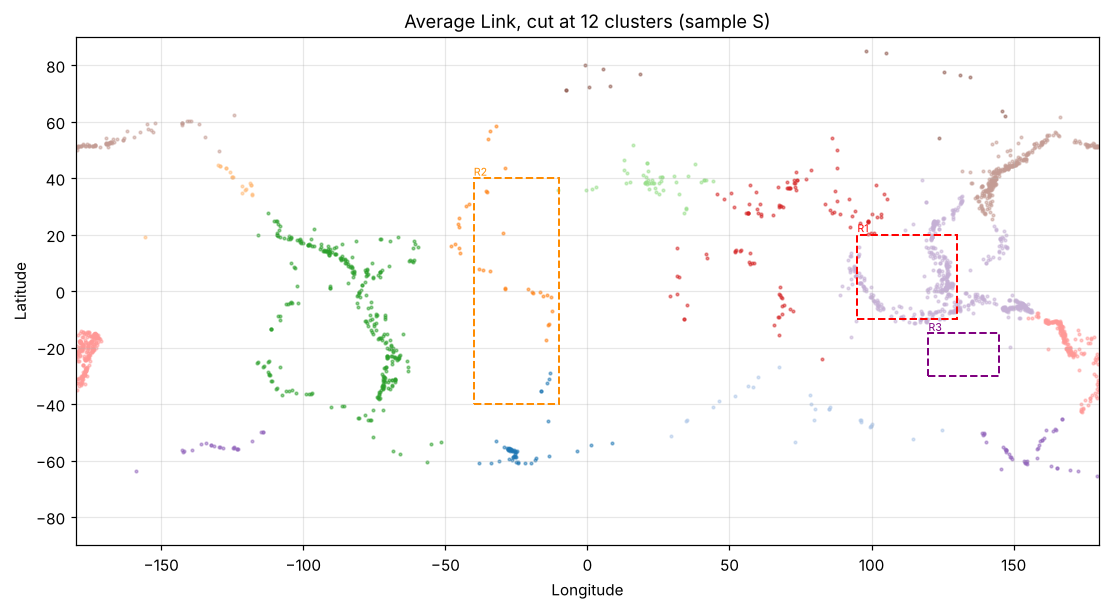

In [33]:
results3["figures"]["average_link"]


In [34]:
print("Single Link cluster sizes:"); display(results3["size_single"])
print("Average Link cluster sizes:"); display(results3["size_average"])


Single Link cluster sizes:
Average Link cluster sizes:


,cluster,size
0,5,1903
1,4,31
2,7,20
3,8,14
4,9,10
5,1,7
6,3,6
7,2,5
8,11,1
9,12,1


,cluster,size
0,10,555
1,8,438
2,12,337
3,5,306
4,7,104
5,9,66
6,1,52
7,6,49
8,3,32
9,2,27


In [35]:
print(results3["qc_discussion"])


Cluster-size coefficient of variation: Single Link=3.28 (largest cluster: 1903 of 2000 points), Average Link=1.14 (largest cluster: 555 of 2000 points). Single Link produced the more unbalanced split here, which matches the direction predicted in P3: Single Link's minimum-distance linkage criterion is vulnerable to a thin chain of points connecting two otherwise separate masses into one cluster, producing one dominant cluster and several small remainders, while Average Link's mean-distance criterion resists being dragged along a chain and tends to keep clusters more balanced in size.


## Question D — the chaining effect


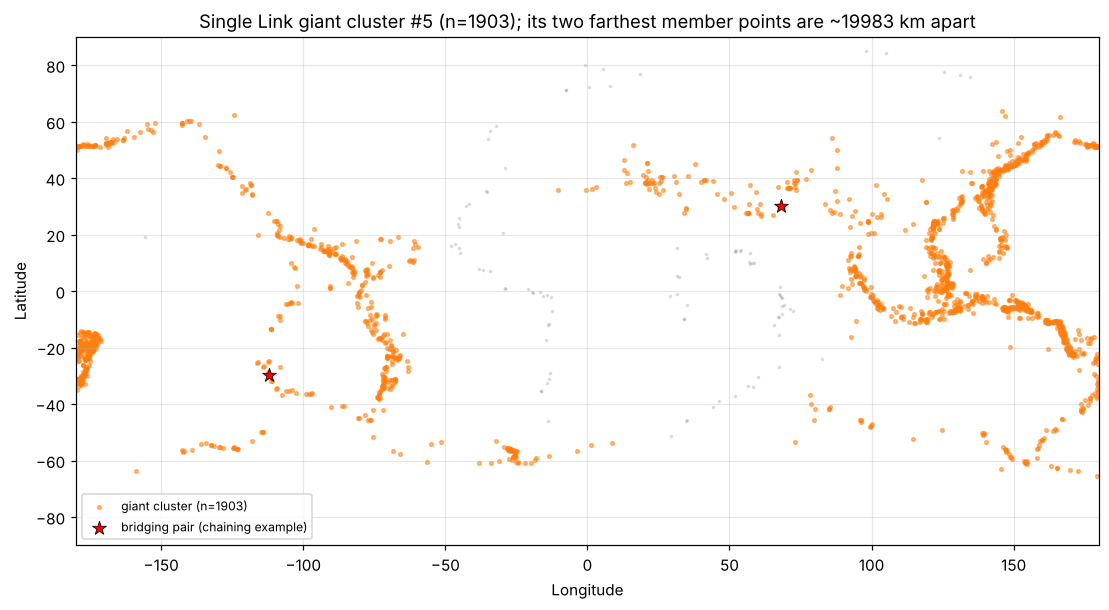

In [36]:
results3["figures"]["chain"]


In [37]:
print(results3["qd_discussion"])


Single Link's giant cluster #5 (n=1903 of the 2000 points in S) contains two points about 19983 km apart (highlighted on the map), far more than the within-cluster distances seen in any of the smaller clusters. By definition, Single Link measures the distance between two clusters as the *minimum* distance between any pair of their members, so merging continues as long as there exists *some* close pair bridging two groups -- even if the rest of the two groups are far apart. A thin, almost-continuous chain of earthquakes (e.g. along a subduction zone or ridge) is exactly this kind of bridge. Average Link instead uses the *mean* distance over all pairs between two clusters, so a single close pair is diluted by many far-apart pairs and is not enough on its own to trigger a merge; this is why Average Link tends to avoid this specific failure mode. For scenario A (zoning), this chaining is a clear problem, since it produces one very large, geographically incoherent zone instead of several de

# Phase 4 — Evaluation and conclusion


In [38]:
import src.phase4 as _phase4_mod
importlib.reload(_phase4_mod)
from src.phase4 import run_phase4

results4 = run_phase4(df=results["df"], sample_S=results2["sample_S"],
                       phase2_results=results2, phase3_results=results3)
print("DBSCAN eps used for the 4-method comparison (selected for scenario B in Phase 3-B):",
      results3["final_eps_scenario_b"], "km")


DBSCAN eps used for the 4-method comparison (selected for scenario B in Phase 3-B): 75 km


## Question A — evaluation on the shared sample S
Four label sets on the same 2000 points of S: K-Means and DBSCAN labels extracted (by `record_id`) from the full-data runs selected in Phases 2-3, next to Single Link and Average Link, which were fit on S directly.


In [39]:
results4["qa_summary_table"]  # n_clusters, largest/median size, # small clusters, coverage%, Silhouette


,method,n_clusters,largest_cluster_size,median_cluster_size,n_clusters_10_19_points,coverage_pct,silhouette
0,"K-Means (k=12, full data -> S)",12,345,141.0,0,100.0,0.504
1,"DBSCAN (eps=75 km, full data -> S)",150,265,2.0,137,83.1,0.105
2,"Single Link (fit on S, 12 clusters)",12,1903,6.5,9,100.0,-0.306
3,"Average Link (fit on S, 12 clusters)",12,555,59.0,2,100.0,0.445


Same-extent maps, all four methods:


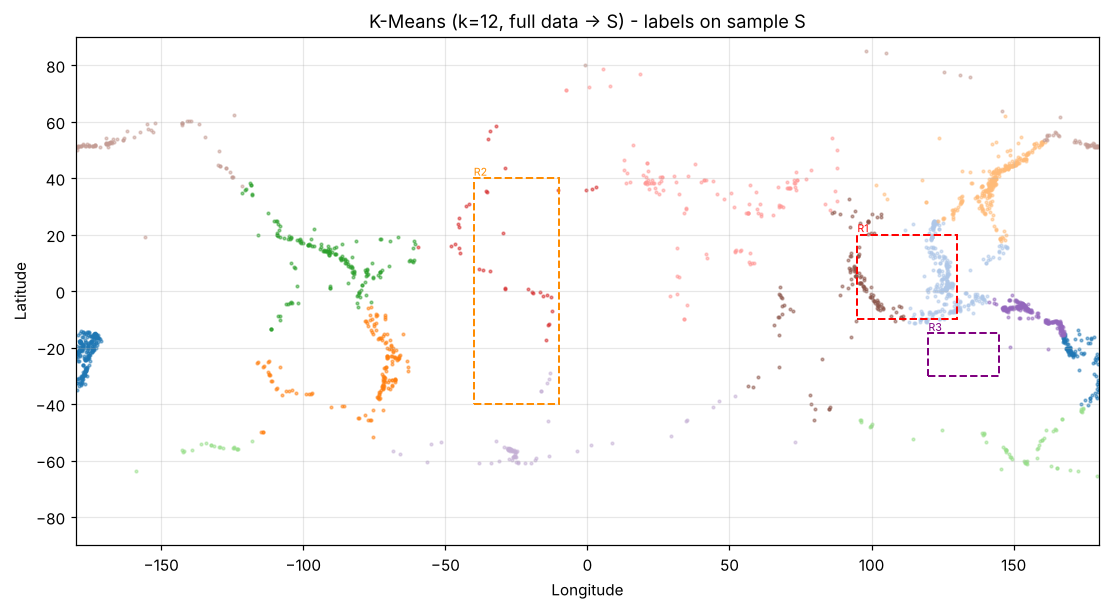

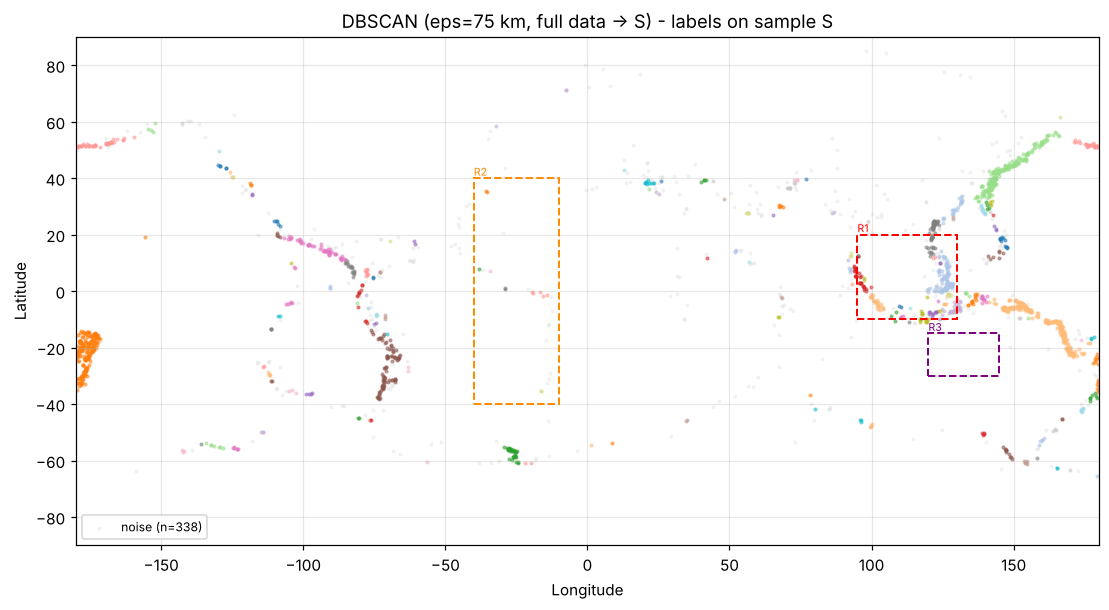

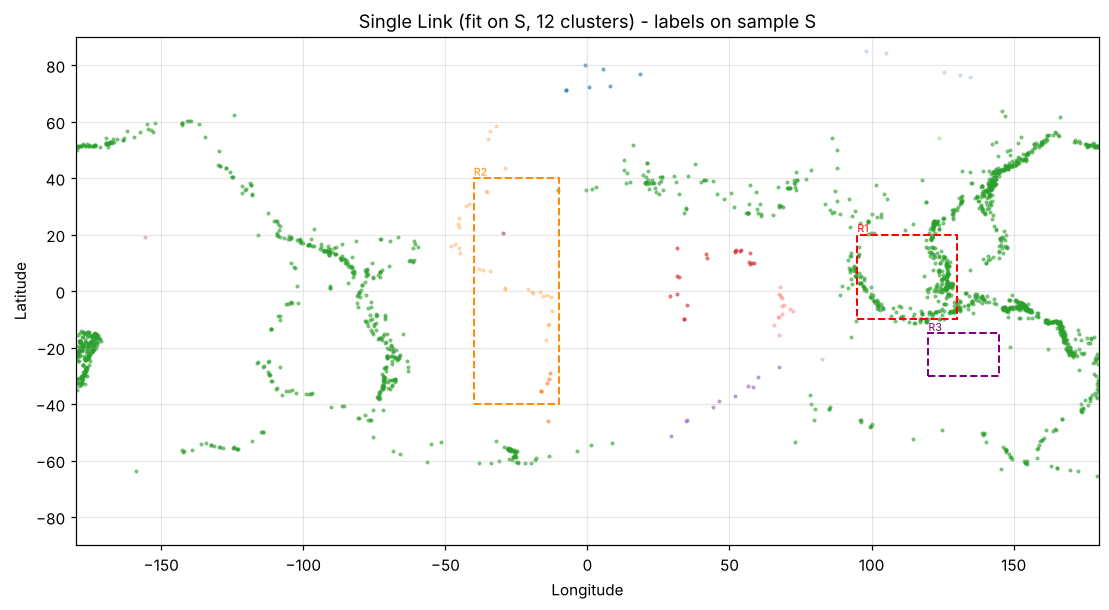

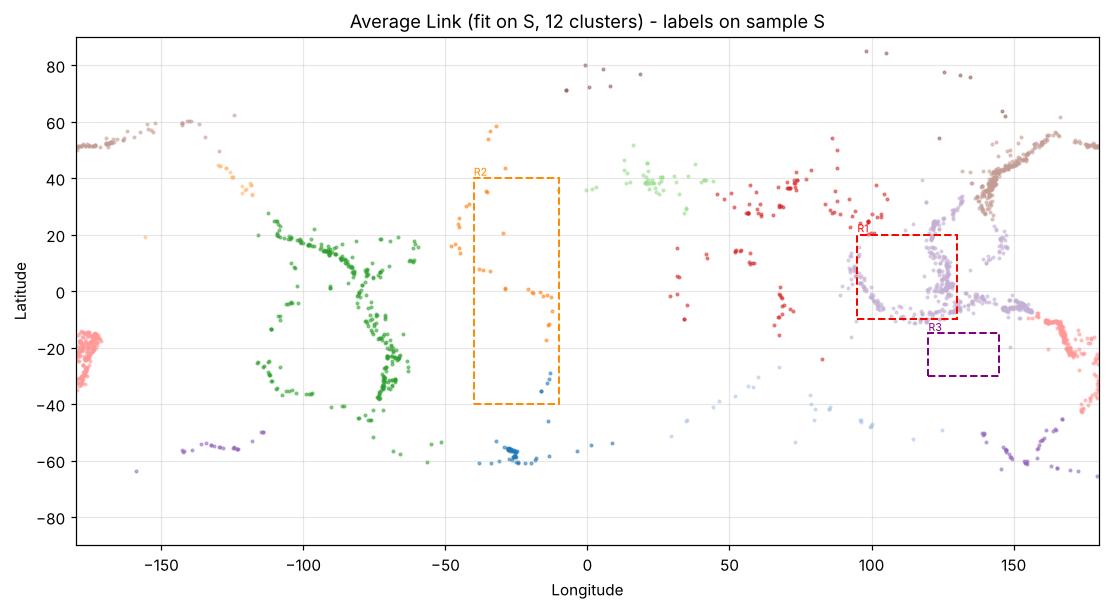

In [40]:
for name, fig in results4["figures"].items():
    display(fig)


Pairwise ARI (all 6 pairs; DBSCAN's noise label is kept as its own group):


In [41]:
results4["qa_ari_table"]


,method_1,method_2,ARI
0,"K-Means (k=12, full data -> S)","DBSCAN (eps=75 km, full data -> S)",0.460
1,"K-Means (k=12, full data -> S)","Single Link (fit on S, 12 clusters)",0.017
2,"K-Means (k=12, full data -> S)","Average Link (fit on S, 12 clusters)",0.575
3,"DBSCAN (eps=75 km, full data -> S)","Single Link (fit on S, 12 clusters)",-0.006
4,"DBSCAN (eps=75 km, full data -> S)","Average Link (fit on S, 12 clusters)",0.287
5,"Single Link (fit on S, 12 clusters)","Average Link (fit on S, 12 clusters)",0.041


In [42]:
results4["qa_ari_matrix"]


,"K-Means (k=12, full data -> S)","DBSCAN (eps=75 km, full data -> S)","Single Link (fit on S, 12 clusters)","Average Link (fit on S, 12 clusters)"
"K-Means (k=12, full data -> S)",1.000000,0.460469,0.017155,0.574842
"DBSCAN (eps=75 km, full data -> S)",0.460469,1.000000,-0.006086,0.287046
"Single Link (fit on S, 12 clusters)",0.017155,-0.006086,1.000000,0.040910
"Average Link (fit on S, 12 clusters)",0.574842,0.287046,0.040910,1.000000


In [43]:
print(results4["qa_eval_discussion"])


Summary table: K-Means and the two hierarchical methods label every point of S (coverage=100%); DBSCAN's coverage on S is 83.1% because S is a sparser subsample of the full data, so the eps selected on the full data leaves some of S's points without enough neighbors. Pairwise ARI ranges from -0.006 (lowest: DBSCAN (eps=75 km, full data -> S) vs. Single Link (fit on S, 12 clusters)) to 0.575 (highest: K-Means (k=12, full data -> S) vs. Average Link (fit on S, 12 clusters)). None of the pairwise ARI values is close to 1, so the four methods do not agree strongly on a single partition of S; this is expected given how differently each method defines a cluster (fixed-k Voronoi cells vs. density reachability vs. two different linkage criteria), and a high ARI between two of them would not by itself mean that partition is 'more correct', only that those two methods happen to agree more. Silhouette, where defined, should be read together with coverage and cluster count from the same table: a m

### Resampling stability
Three 80%-of-S subsets (seeds s, s+1, s+2); K-Means (k=12), Single Link and Average Link run on each (9 runs total); pairwise ARI on each pair's common points (9 ARI values).


In [44]:
results4["stability_pairs_table"]  # 9 rows: method x subset-pair


,method,subset_pair,n_common_points,ARI
0,K-Means (k=12),seed429 vs seed430,1270,0.952
1,K-Means (k=12),seed429 vs seed431,1280,0.950
2,K-Means (k=12),seed430 vs seed431,1285,0.906
3,Single Link (12 clusters),seed429 vs seed430,1270,0.578
4,Single Link (12 clusters),seed429 vs seed431,1280,0.418
5,Single Link (12 clusters),seed430 vs seed431,1285,0.839
6,Average Link (12 clusters),seed429 vs seed430,1270,0.820
7,Average Link (12 clusters),seed429 vs seed431,1280,0.902
8,Average Link (12 clusters),seed430 vs seed431,1285,0.916


In [45]:
results4["stability_summary_table"]  # mean/range of ARI per method


,method,mean_ARI,range_ARI
0,K-Means (k=12),0.936,0.046
1,Single Link (12 clusters),0.612,0.421
2,Average Link (12 clusters),0.879,0.096


In [46]:
print(results4["stability_discussion"])


Mean/range of the three pairwise ARIs per method: K-Means (k=12): mean=0.936, range=0.046; Single Link (12 clusters): mean=0.612, range=0.421; Average Link (12 clusters): mean=0.879, range=0.096. In this experiment, K-Means (k=12) was the most stable under 80% resampling and Single Link (12 clusters) the least. A plausible mechanism: at every iteration K-Means recomputes each cluster's center as the *mean* of all the points currently assigned to it, so a single center summarizes the whole cluster rather than any one point in it -- removing or adding a handful of points out of an 80% resample barely moves that mean. K-Means therefore re-fits its k=12 centers on whichever 80% of points is present, and because the centers move smoothly as points are added/removed, the resulting Voronoi partition changes gradually. Single Link, by contrast, depends on the single closest pair bridging two groups at each merge step, so removing or keeping a handful of 'bridge' points can flip whether two lar

In [47]:
print(results4["best_numeric_but_not_best_fit"])


Concrete example: by the single numeric score, K-Means (k=12, full data -> S) and Average Link (fit on S, 12 clusters) agree the most (ARI=0.575) among the six pairs above, and in the stability experiment K-Means (k=12) posts the highest mean ARI. Neither fact alone identifies the best clustering for either project scenario: scenario A additionally needs full coverage and a describable, roughly even number of regions (which rules out whichever of these methods leaves a large noise fraction or one dominant giant cluster, even if its agreement/stability score is high), and scenario B additionally needs genuine density-based structure discovery (which a fixed-k, always-covers-everything method does not attempt, however stable its output is run to run). The final recommendation below (Question B) is therefore based on the numeric tables together with each scenario's actual requirements, not on picking the single highest score.


## Question B — conclusion


In [48]:
results4["verdict_table"]  # P1-P4: confirmed / rejected / partially confirmed, with evidence


,prediction,verdict,evidence
0,P1,Confirmed,Phase 2-C: region 'R1_Indonesia_Philippines' spans 2 K-Means clusters at k=12 (table + Phase 2 fig. 03).
1,P2,Partially confirmed,"Phase 3-A table: noise% decreases and largest-cluster share increases monotonically with eps (fig. 01); Phase 3-B table shows no single tested eps keeps every Phase-1 region's noise below the 30% criterion without merging regions, supporting the 'no single eps handles both scales well' half of P2."
2,P3,Confirmed,"Phase 3-C: cluster-size coefficient of variation, Single Link=3.28 vs. Average Link=1.14 (table + figs. 02-03); Phase 3-D chaining example (fig. 04)."
3,P4,Confirmed,"Phase 4-A table: only K-Means reaches 100% coverage with a fixed, describable number of clusters; only DBSCAN/the density-based methods leave points unlabeled as noise instead of forcing them into a cluster (qa_summary_table)."


In [49]:
import json
print(json.dumps(results4["final_recommendation"], indent=2))
print()
print(results4["same_algorithm_note"])


{
  "scenario_A": {
    "algorithm": "K-Means, k=12",
    "representation": "3D unit-sphere coordinates (x,y,z)",
    "parameters": "n_init=10, seed=429",
    "evidence": [
      "100% coverage on both the full data and on S (qa_summary_table), which scenario A's 'every earthquake assigned to one region' requirement needs directly -- DBSCAN and the two hierarchical runs either leave noise or are only defined on the 2000-point sample S. Even if Single Link and Average Link were instead run on the full dataset (not just S), this would not close the gap for scenario A: on S, Single Link's size coefficient of variation is already 3.28 with one giant cluster of 1903 of 2000 points (Phase 3-C/D), i.e. a single dominant, geographically incoherent cluster that already violates scenario A's 'describable zones' requirement at sample scale and would only chain further on denser full data; Average Link is more balanced (CV=1.14) but still gives no numerical guarantee against merging distinct Phase

# Bonus Q.A — Controlled Perturbation (optional, +5)
5% of the full dataset, displaced 10-20 km in a random geographic direction (seed s+3); K-Means and DBSCAN re-run with the project's selected parameters, original vs. perturbed.


**Perturbation method and seed (reproducibility record):**
- A uniformly random 5% subset of the full cleaned dataset is selected with `numpy.random.RandomState(seed=S_PLUS_3)` (`seed = s + 3`, the project's base seed `s` plus 3, kept distinct from the seeds already used in Phases 2-4 so this perturbation experiment doesn't reuse randomness from any earlier step).
- For each selected point, a random **bearing** (direction) is drawn uniformly from 0-360 degrees and a random **distance** is drawn uniformly from 10-20 km, both from that same seeded generator, so the whole perturbation is fully reproducible from `S_PLUS_3` alone.
- The point is then displaced along that bearing by that distance over the Earth's surface (great-circle displacement, not a flat lat/lon shift), and K-Means/DBSCAN are re-run with the project's already-selected parameters (same `k`, same `eps`, same algorithm seed `S_BASE`) on this perturbed dataset.
- The boolean mask of which 5% of rows were perturbed is saved to `qa_perturbation_mask.csv` so the experiment can be audited or repeated exactly.


In [50]:
import src.bonus as _bonus_mod
importlib.reload(_bonus_mod)
from src.bonus import run_bonus_qa, run_bonus_qb

bonus_qa = run_bonus_qa(df=results["df"], phase2_results=results2, phase3_results=results3)
bonus_qa["qa_table"]


,method,ARI_orig_vs_perturbed,n_clusters_orig,n_clusters_pert,largest_cluster_orig,largest_cluster_pert,noise_pct_orig,noise_pct_pert,n_perturbed_points,n_perturbed_changed,pct_perturbed_changed,n_unperturbed_points,n_unperturbed_changed,pct_unperturbed_changed
0,K-Means (k=12),1.000,12,12,3799,3799,NaN,NaN,1162,0,0.0,22070,0,0.000
1,DBSCAN (eps=75 km),0.993,179,175,3438,3438,17.2,17.26,1162,10,0.9,22070,71,0.322


In [51]:
print(bonus_qa["qa_discussion"])


ARI (original vs. perturbed labels, same records): K-Means=1.000, DBSCAN=0.993. In this single perturbation run, K-Means shows the higher ARI and is therefore the more robust of the two here. K-Means's centers are an average over thousands of points, so moving 1162 points (5% of the data) by only 10-20 km barely shifts any center, which is consistent with a high ARI and almost no membership change among unperturbed points; DBSCAN's labeling depends on each point's local neighbor count, so a 10-20 km shift can push a point across the eps boundary (into or out of noise, or into a neighboring cluster) especially in sparser regions, which can also disturb a modest number of other points connected to it through density-reachability chains. The unperturbed points that still changed membership (reported in the table) show this knock-on effect directly: it is not limited to exactly the 5% of points that were moved. A single random 5% perturbation is only one draw; it tells us this specific dra

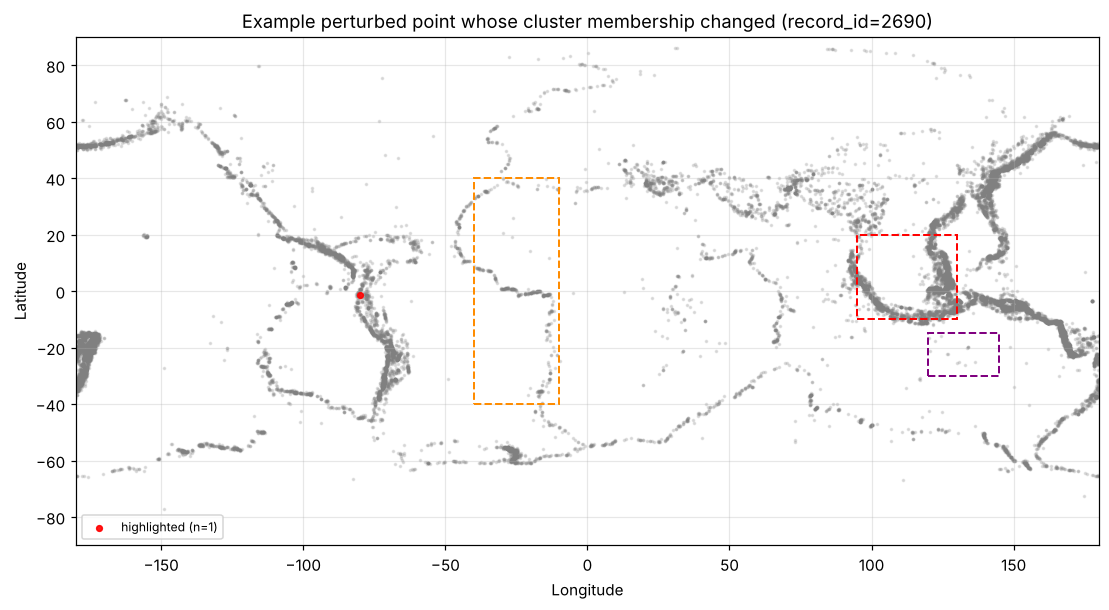

In [52]:
if bonus_qa["figures"]["example"] is not None:
    display(bonus_qa["figures"]["example"])


# Bonus Q.B — HDBSCAN (optional, +5)
HDBSCAN vs. DBSCAN on the shared sample S, with DBSCAN's eps re-tuned on S itself.


In [53]:
bonus_qb = run_bonus_qb(df=results["df"], sample_S=results2["sample_S"])
print(bonus_qb["hdb_explanation"])


HDBSCAN builds a hierarchy of DBSCAN-like clusterings across a *range* of density thresholds (via a mutual-reachability distance and a minimum spanning tree) and then extracts, for each branch, the cluster split that is most stable across that range, instead of committing to one fixed global eps the way plain DBSCAN does. In practice this lets it keep a sparse-but-genuine group as one cluster at a looser density threshold, while still separating a much denser group at a tighter threshold in a different branch of the same hierarchy -- plain DBSCAN, with a single eps, is forced to pick one density scale for the whole dataset at once.


In [54]:
bonus_qb["candidates_table"]  # DBSCAN eps candidates tried on S


,eps_km,n_clusters,noise_pct
0,211.6,22,36.8
1,418.1,15,17.1
2,906.7,10,5.7


In [55]:
print(bonus_qb["eps_choice_reason"])


Candidates were read off S's own 10th-neighbor-distance distribution (median=211.6 km, 75th pct=418.1 km, 90th pct=906.7 km), since Phase 3's full-data eps values assume a denser input than the 2000-point S. eps=211.6 km is the tightest of the tested values that still keeps overall noise under 50% on S (see candidates table).


In [56]:
bonus_qb["overall_table"]


,method,n_clusters,noise_pct,silhouette
0,"DBSCAN (eps=211.6 km, min_samples=10)",22,36.8,0.573
1,"HDBSCAN (min_cluster_size=10, min_samples=10)",39,24.6,0.552


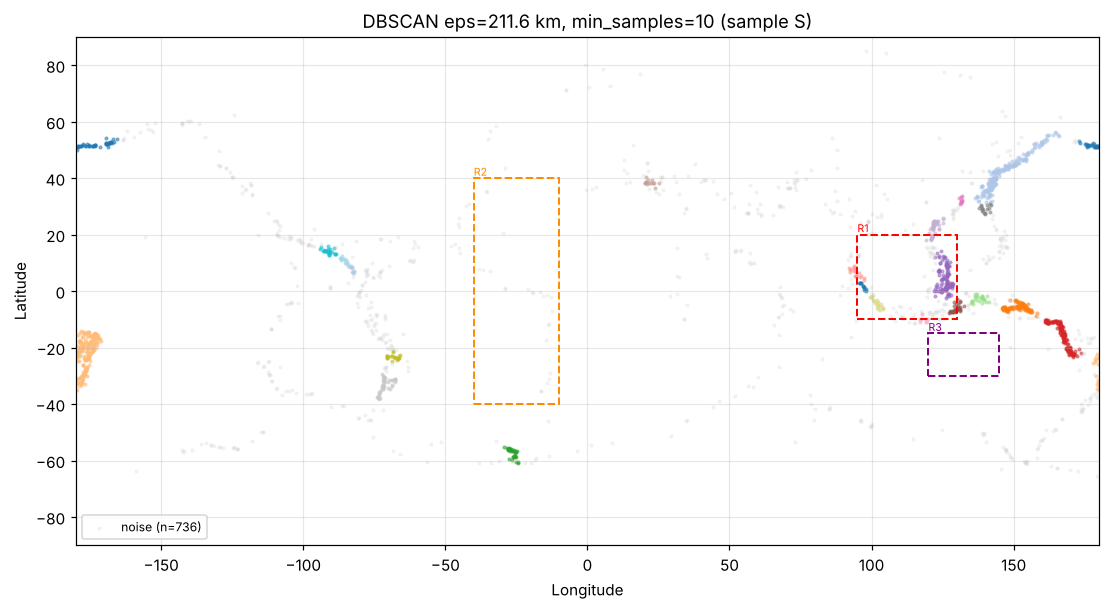

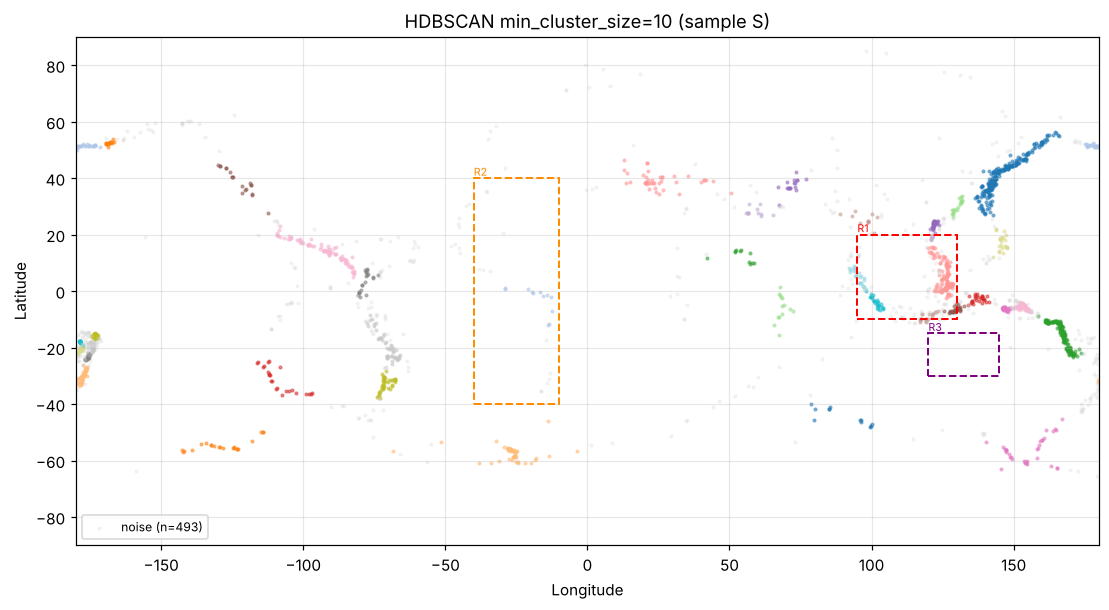

In [57]:
display(bonus_qb["figures"]["dbscan"])
display(bonus_qb["figures"]["hdbscan"])


In [58]:
bonus_qb["region_table"]  # per Phase-1 region: n in S, DBSCAN noise%, HDBSCAN noise%


,region,n_in_S,dbscan_noise_pct,hdbscan_noise_pct
0,R1_Indonesia_Philippines,256,24.2,19.9
1,R2_MidAtlanticRidge,25,100.0,52.0
2,R3_CentralAustralia,0,0.0,0.0


In [59]:
print(bonus_qb["verdict_discussion"])


Overall noise: DBSCAN=36.8%, HDBSCAN=24.6% (table above); per-region noise is broken down in the regions table. Lower noise alone is not evidence that HDBSCAN is 'better' for scenario B: scenario B wants genuine belts/clusters, not simply fewer points labeled noise, so the per-region table and cluster count must be read together with the noise numbers. If HDBSCAN both (a) lowers noise in the sparser Phase-1 region(s) and (b) keeps the dense region's main cluster from fragmenting or merging with the others relative to DBSCAN, that is real evidence of a better multi-scale fit for scenario B; if instead its lower overall noise comes mostly from pulling in points at the edge of the dense region while the sparse region's noise barely improves, the apparent gain is weaker than the single overall noise% number suggests. The trade-off we accept by choosing one over the other is explicit: a method that keeps more sparse, low-density structure out of the noise class (HDBSCAN, typically) usually 

## Download outputs (to attach to the report)
All files are saved under `outputs/phase1/`, `outputs/phase2/`, `outputs/phase3/`, `outputs/phase4/` and `outputs/bonus/`; the cell below zips and downloads all of them together.


In [ ]:
!zip -r all_phases_outputs.zip outputs/phase1 outputs/phase2 outputs/phase3 outputs/phase4 outputs/bonus
from google.colab import files
files.download("all_phases_outputs.zip")